# Exploratory Data Analysis for IBM Employee Attrition 

## Section 1: Introduction and Problem Definition
### Problem scope
Identify factors associated with employee attrition.

Which employee, job, compensation, and satisfaction characteristics are associated with higher attrition rates?

#### Questions we're trying to answer
TODO

#### Dataset description
dataset link : https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/data

The dataset has 1,470 employee records and 35 columns - 31 after dropping constant and ID columns. The target is Attrition (Yes/No): 237 employees left out of 1,470 (16.1%).

## Section 2: Data Understanding and Preparation

### Libraries & Data Loading

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
df = pd.read_csv("./data.csv")
pd.options.display.max_columns = None
pd.options.display.max_rows = 100

df.shape

(1470, 35)

In [23]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

All types are int64 or str, no special conversion needed for now

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


seems there is no missing values, to confirm: 

In [26]:
df.isna().sum().sum()

np.int64(0)

checking duplicated values:

In [27]:
df.duplicated().sum()

np.int64(0)

our data has no missing values or duplicated rows

considering first 5 rows from the dataset  , we can see that EmployeeCount column and Over18 columns maybe useless

In [28]:
df.nunique().sort_values() 

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

confirmed that columns "EmployeeCount","Over18" are unneceasssry in addition to "StandardHours", we can drop them

In [29]:
df['EmployeeNumber'].nunique()

1470

"EmployeeNumber" acts as ID , we can drop it also.

In [30]:
df = df.drop(columns=["EmployeeCount","Over18","StandardHours","EmployeeNumber"])

Lets see how is the attrition rate in the company

In [31]:
df['Attrition_numeric'] = df['Attrition'].map({"Yes":1,"No":0})
print(f"{df['Attrition_numeric'].mean():.1%}", df['Attrition_numeric'].sum() )

16.1% 237


16.1% of employees left (237 of 1,470). This is the baseline used for every comparison below.

### Categorical And Numerical Columns

considering the number of unique values, these columns could be categorical columns:
```
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
JobRole                        9
Age                           43
```

although "TrainingTimeLastYear" has low unique values , it is not categorical # Maybe removing this cell is better

In [32]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesLastYear       int64
WorkLifeBalance             int64
YearsAtCompany              int64
YearsInCurrentRole          int64
YearsSinceLast

since we have only object and int64 datatypes , we can initially classify them: 

In [33]:
cat_cols = df.select_dtypes(include=["object", 'str']).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

In [34]:
cat_cols

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'OverTime']

In [35]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition_numeric']

A lot of the categorical columns considering the data from kaggle and columns labels uses integers, we will convert them for readablity

lets explore columns that have small unique values number and convert them:

In [36]:
for col in num_cols:
  if df[col].nunique()< 10:
    print(f"{col} : {df[col].unique()}")

Education : [2 1 4 3 5]
EnvironmentSatisfaction : [2 3 4 1]
JobInvolvement : [3 2 4 1]
JobLevel : [2 1 3 4 5]
JobSatisfaction : [4 2 3 1]
PerformanceRating : [3 4]
RelationshipSatisfaction : [1 4 2 3]
StockOptionLevel : [0 1 3 2]
TrainingTimesLastYear : [0 3 2 5 1 4 6]
WorkLifeBalance : [1 3 2 4]
Attrition_numeric : [1 0]


most of the columns are mentiond in kaggle website to be categorical, except JobLevel ,StockOptionLevel and TrainingTimesLastYear (These are not mentioned)

obviously TrainingTimesLastYear is not a categorical column even if it has small number of values


In [37]:
from pandas.api.types import CategoricalDtype

# Mapping dictionaries
education = {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"} 
environment_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_involvement = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
performance_rating = {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"} 
relationship_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
worklife_balance = {1: "Bad", 2: "Good", 3: "Better", 4: "Best"} 
job_map = {1: "Entry", 2: "Intermediate", 3: "Senior", 4: "Lead", 5: "Executive"} 
stock_map = {0: "None", 1: "Low", 2: "Medium", 3: "High"} 

# Ordered categories for each variable
ordered_mappings = {
    "Education": list(education.values()),
    "EnvironmentSatisfaction": list(environment_satisfaction.values()),
    "JobInvolvement": list(job_involvement.values()),
    "JobSatisfaction": list(job_satisfaction.values()),
    "PerformanceRating": list(performance_rating.values()),
    "RelationshipSatisfaction": list(relationship_satisfaction.values()),
    "WorkLifeBalance": list(worklife_balance.values()),
    "JobLevel": list(job_map.values()),
    "StockOptionLevel": list(stock_map.values())
}

# Mapping numeric codes to labels
df["Education"] = df["Education"].map(education)
df["EnvironmentSatisfaction"] = df["EnvironmentSatisfaction"].map(environment_satisfaction)
df["JobInvolvement"] = df["JobInvolvement"].map(job_involvement)
df["JobSatisfaction"] = df["JobSatisfaction"].map(job_satisfaction)
df["PerformanceRating"] = df["PerformanceRating"].map(performance_rating)
df["RelationshipSatisfaction"] = df["RelationshipSatisfaction"].map(relationship_satisfaction)
df["WorkLifeBalance"] = df["WorkLifeBalance"].map(worklife_balance)
df["JobLevel"] = df["JobLevel"].map(job_map)
df["StockOptionLevel"] = df["StockOptionLevel"].map(stock_map)

# Convert all to ordered categorical
for col, order in ordered_mappings.items():
    dtype = CategoricalDtype(categories=order, ordered=True)
    df[col] = df[col].astype(dtype)

now we can check our datatypes to make sure everything is right 

In [38]:
df.dtypes

Age                            int64
Attrition                        str
BusinessTravel                   str
DailyRate                      int64
Department                       str
DistanceFromHome               int64
Education                   category
EducationField                   str
EnvironmentSatisfaction     category
Gender                           str
HourlyRate                     int64
JobInvolvement              category
JobLevel                    category
JobRole                          str
JobSatisfaction             category
MaritalStatus                    str
MonthlyIncome                  int64
MonthlyRate                    int64
NumCompaniesWorked             int64
OverTime                         str
PercentSalaryHike              int64
PerformanceRating           category
RelationshipSatisfaction    category
StockOptionLevel            category
TotalWorkingYears              int64
TrainingTimesLastYear          int64
WorkLifeBalance             category
Y

In [39]:
cat_cols = df.select_dtypes(include=["object",'category','str']).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

In [40]:
for col in cat_cols:
  print(f"{col}: {df[col].unique()}")

BusinessTravel: <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str
Department: <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
Education: ['College', 'Below College', 'Master', 'Bachelor', 'Doctor']
Categories (5, str): ['Below College' < 'College' < 'Bachelor' < 'Master' < 'Doctor']
EducationField: <StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str
EnvironmentSatisfaction: ['Medium', 'High', 'Very High', 'Low']
Categories (4, str): ['Low' < 'Medium' < 'High' < 'Very High']
Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
JobInvolvement: ['High', 'Medium', 'Very High', 'Low']
Categories (4, str): ['Low' < 'Medium' < 'High' < 'Very High']
JobLevel: ['Intermediate', 'Entry', 'Senior', 'Lead', 'Executive']
Categories (5, str): ['Entry' < 'Intermediate' < 'Senior' < 'Lead' < 'Executive']
Job

In [41]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'HourlyRate',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition_numeric']

In [42]:
cat_cols

['BusinessTravel',
 'Department',
 'Education',
 'EducationField',
 'EnvironmentSatisfaction',
 'Gender',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'OverTime',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'WorkLifeBalance']

## Section 3: Univariate Analysis

### Numerical Features Distributions

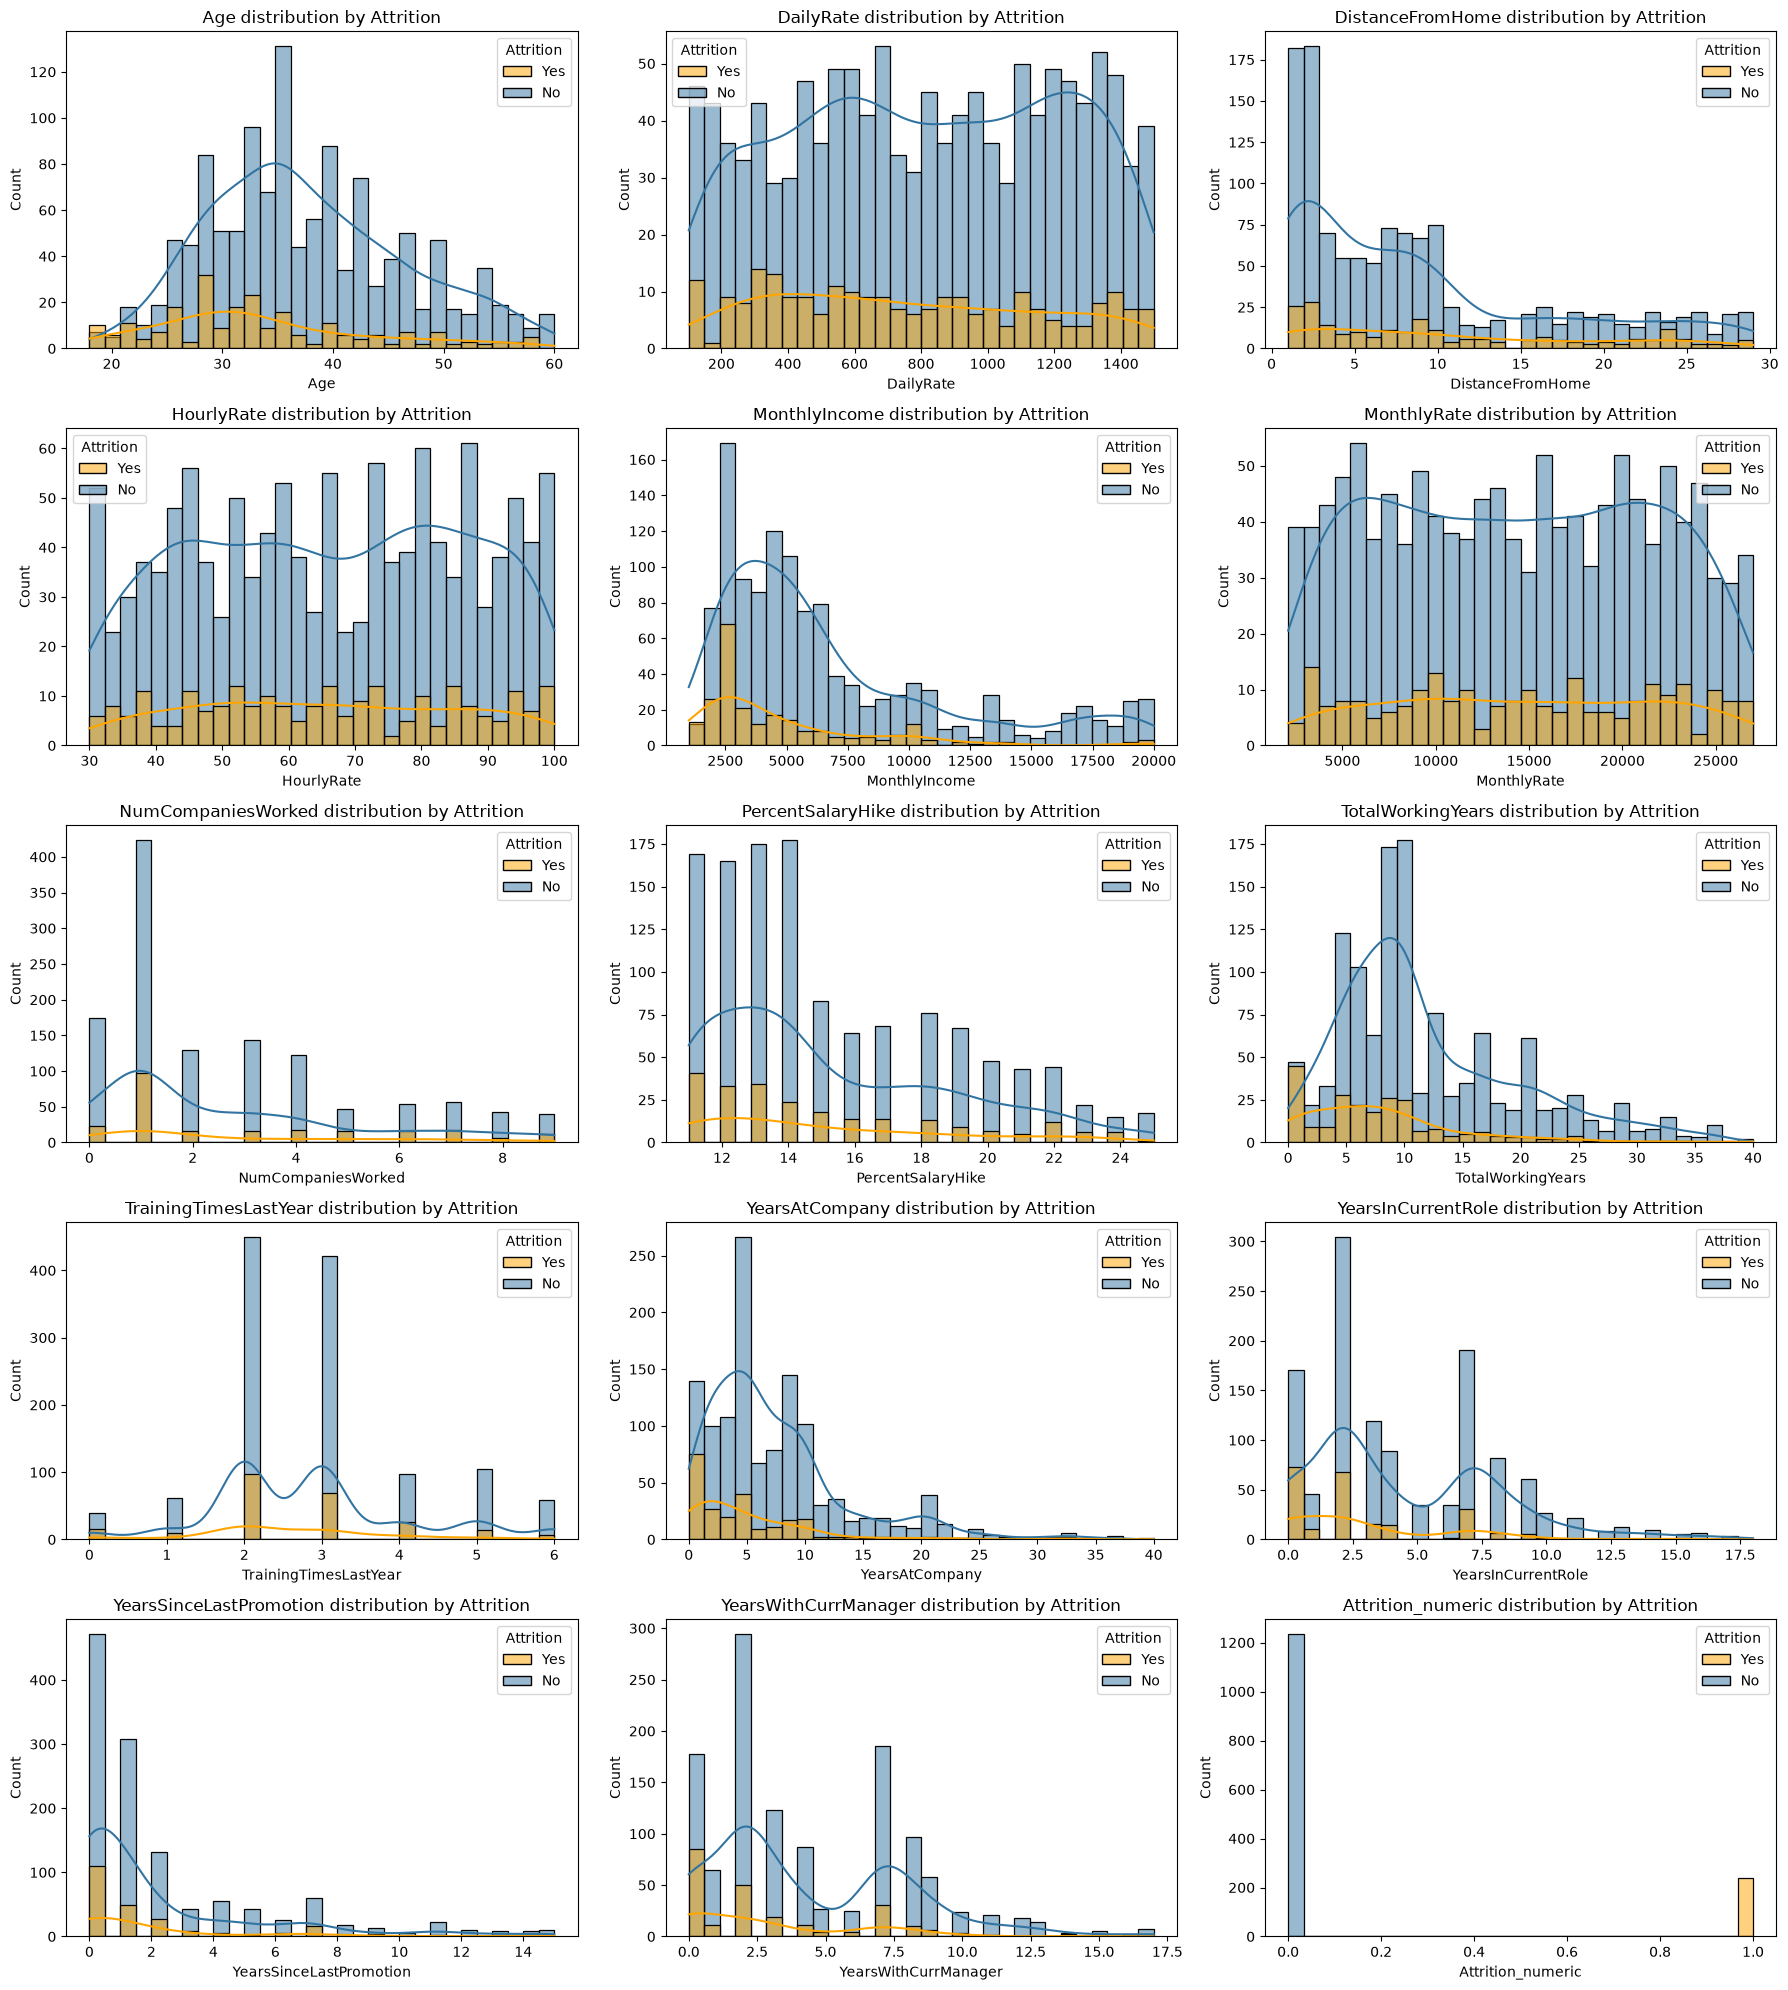

In [51]:
color_map = {"Yes": "orange", "No": "#3274A1"}

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        multiple="layer",
        bins=30,
        
        ax=axes[idx],
        kde=True,
        palette=color_map
    )
    axes[idx].set_title(f"{col} distribution by Attrition")

# Remove empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()




Section 3

- Numerical feature distributions
- Categorical feature distributions
- Interesting observations


Section 4
Relationships Between Features
- Numerical feature correlations
- Relationships between important numerical features
- Potentially redundant features


Section 5
Attrition Analysis
- Career history
- Compensation
- Job characteristics and satisfaction
- Work conditions
- Demographics
- Education and development
- Organization
Each subsection should contain relevant visualizations, attrition-rate tables, and written observations.


Section 6
Conclusion and Key Findings
- Most important observations
- Weak or insignificant associations
- Limitations of the analysis